# Practical 2: Foundations of statistics

## Aim
Descriptive statistics, histogram, group means and cross-tabulation on the Teaching Ratings data.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ratings = pd.read_csv("TeachingRatings.csv")

In [3]:
print("Shape:", ratings.shape)
print(ratings.head(10))
print("\nColumns:", list(ratings.columns))
print("Dataset type: cross-sectional (many instructors observed once)")

Shape: (463, 13)
   rownames minority  age  gender  ... tenure  students  allstudents prof
0         1      yes   36  female  ...    yes        24           43    1
1         2       no   59    male  ...    yes        17           20    2
2         3       no   51    male  ...    yes        55           55    3
3         4       no   40  female  ...    yes        40           46    4
4         5       no   31  female  ...    yes        42           48    5
5         6       no   62    male  ...    yes       182          282    6
6         7       no   33  female  ...    yes        33           41    7
7         8       no   51  female  ...    yes        25           41    8
8         9       no   33  female  ...    yes        48           60    9
9        10       no   47    male  ...     no        16           19   10

[10 rows x 13 columns]

Columns: ['rownames', 'minority', 'age', 'gender', 'credits', 'beauty', 'eval', 'division', 'native', 'tenure', 'students', 'allstudents', 'prof

In [4]:
s = ratings["students"]
print("\nStudents - mean: %.4f, median: %.1f, min: %d, max: %d" % (s.mean(), s.median(), s.min(), s.max()))


Students - mean: 36.6242, median: 23.0, min: 5, max: 380


In [5]:
print("\nDescriptive statistics:")
print(ratings.describe().round(4))


Descriptive statistics:
       rownames       age    beauty      eval  students  allstudents      prof
count  463.0000  463.0000  463.0000  463.0000  463.0000     463.0000  463.0000
mean   232.0000   48.3650    0.0000    3.9983   36.6242      55.1771   45.4341
std    133.8008    9.8027    0.7886    0.5549   45.0185      75.0728   27.5089
min      1.0000   29.0000   -1.4505    2.1000    5.0000       8.0000    1.0000
25%    116.5000   42.0000   -0.6563    3.6000   15.0000      19.0000   20.0000
50%    232.0000   48.0000   -0.0680    4.0000   23.0000      29.0000   44.0000
75%    347.5000   57.0000    0.5456    4.4000   40.0000      60.0000   70.5000
max    463.0000   73.0000    1.9700    5.0000  380.0000     581.0000   94.0000


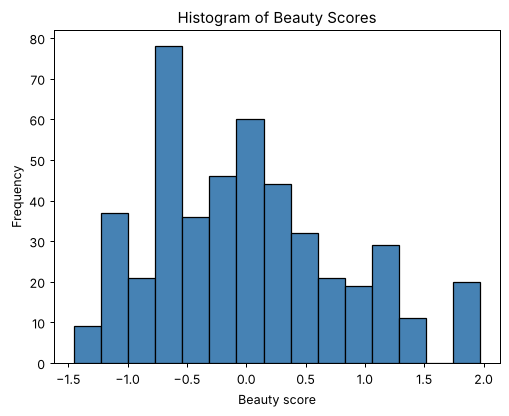

In [6]:
b = ratings["beauty"]
plt.hist(b, bins=15, color="steelblue", edgecolor="black")
plt.title("Histogram of Beauty Scores")
plt.xlabel("Beauty score")
plt.ylabel("Frequency")
plt.show()

In [7]:
print("\nBeauty - mean: %.4f, median: %.4f, std: %.4f" % (b.mean(), b.median(), b.std()))
print("Beauty - skewness: %.4f, kurtosis: %.4f" % (b.skew(), b.kurt()))


Beauty - mean: 0.0000, median: -0.0680, std: 0.7886
Beauty - skewness: 0.5158, kurtosis: -0.3848


In [8]:
print("\nBeauty by gender:")
print(ratings.groupby("gender")["beauty"].agg(["mean", "std"]).round(4))


Beauty by gender:
          mean     std
gender                
female  0.1161  0.8178
male   -0.0845  0.7571


In [9]:
print("\nGender vs tenure (counts):")
print(pd.crosstab(ratings["gender"], ratings["tenure"]))
print("\nGender vs tenure (row %):")
print((pd.crosstab(ratings["gender"], ratings["tenure"], normalize="index") * 100).round(2))


Gender vs tenure (counts):
tenure  no  yes
gender         
female  50  145
male    52  216

Gender vs tenure (row %):
tenure     no    yes
gender              
female  25.64  74.36
male    19.40  80.60


In [10]:
print("\nResult: average beauty score is higher for female instructors (0.1161 vs -0.0845),")
print("the beauty distribution is slightly right-skewed, and 80.60% of male and 74.36% of female")
print("instructors hold tenure.")


Result: average beauty score is higher for female instructors (0.1161 vs -0.0845),
the beauty distribution is slightly right-skewed, and 80.60% of male and 74.36% of female
instructors hold tenure.
